# Persons Involved in the Group

The five students are:
- Elias Hasnaou
- Christian [nom à compléter]
- Reda El Mekkaoui
- Yazid [nom à compléter]
- [à compléter]

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [1]:
%matplotlib inline
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import QuantileRegressor

# Si les CSV ne sont pas à côté du notebook (Colab par exemple), on les télécharge depuis notre dépôt
URL = 'https://raw.githubusercontent.com/eliashas/mini-projet-stochastique/final/rendu_final_concis/'
for f in ['daily_temp_brest.csv', 'yearly_temp_brest.csv', 'yearly_future_co2.csv']:
    if not Path(f).exists():
        urllib.request.urlretrieve(URL + f, f)

rng = np.random.default_rng(0)   # graines fixées : mêmes résultats à chaque exécution
torch.manual_seed(0)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .3})

# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [2]:
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

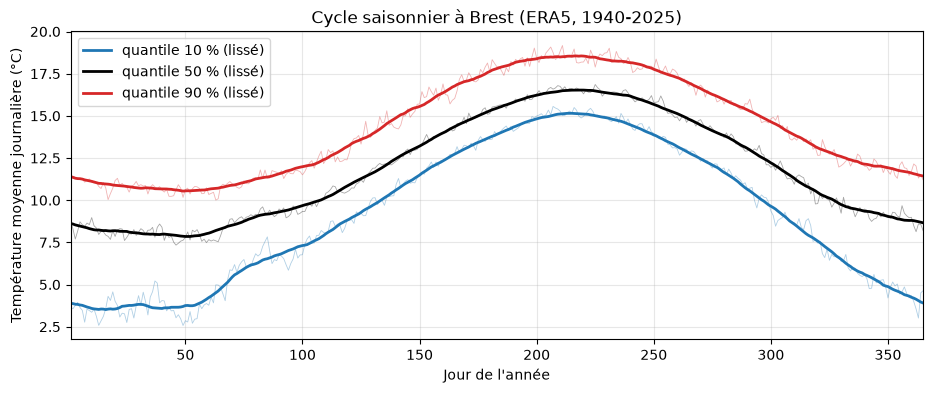

          q10    q50    q90
min       3.5    7.8   10.5
idxmin   16.0   50.0   49.0
max      15.2   16.5   18.6
idxmax  215.0  219.0  219.0


In [3]:
d = daily_temp_brest.assign(date=pd.to_datetime(daily_temp_brest.valid_time))
d = d[~((d.date.dt.month == 2) & (d.date.dt.day == 29))].copy()   # on enlève les 29 février : 365 jours par an
d['jour'] = d.groupby(d.date.dt.year).cumcount() + 1

q = d.groupby('jour')['mean'].quantile([.1, .5, .9]).unstack()
q.columns = ['q10', 'q50', 'q90']
# moyenne glissante sur 31 jours, circulaire (le 31 décembre est suivi du 1er janvier)
lisse = lambda s: pd.concat([s.iloc[-15:], s, s.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
qs = q.apply(lisse)

fig, ax = plt.subplots()
for c, col in zip(qs, ['tab:blue', 'k', 'tab:red']):
    ax.plot(q.index, q[c], color=col, lw=.6, alpha=.35)
    ax.plot(qs.index, qs[c], color=col, lw=2, label=f'quantile {c[1:]} % (lissé)')
ax.set(xlabel='Jour de l\'année', ylabel='Température moyenne journalière (°C)', xlim=(1, 365),
       title='Cycle saisonnier à Brest (ERA5, 1940-2025)')
ax.legend()
plt.show()
print(qs.agg(['min', 'idxmin', 'max', 'idxmax']).round(1))

On a enlevé les 29 février pour avoir 365 jours chaque année. Le lissage est circulaire : pour lisser début janvier,
on utilise aussi fin décembre, puisque le cycle se répète d'une année à l'autre.

**Commentaire.** Le cycle est régulier : le creux est vers le 19 février (médiane 7,8 °C) et le pic vers le 7 août
(16,5 °C). L'amplitude est faible (environ 9 °C) et le maximum arrive bien après le solstice : c'est typique d'un climat
océanique, l'Atlantique se réchauffe lentement en été et rend sa chaleur en hiver. L'écart entre les quantiles 10 % et
90 % est plus grand en hiver (jusqu'à 7,5 °C en janvier) qu'en été (3,4 °C début août) : l'hiver dépend beaucoup de la direction du
vent (air océanique doux ou air continental froid). La courbe à 90 % sert de seuil pour les vagues de chaleur.

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [4]:
DUREE_MIN = 3   # une vague = au moins 3 jours chauds consécutifs

d = d.join(qs, on='jour')
d['chaud'] = d['mean'] > d.q90                    # jour plus chaud que le quantile 90 % de son jour de l'année
d['anomalie'] = d['mean'] - d.q50                 # écart à la médiane du jour (°C)
d['bloc'] = (d.chaud != d.chaud.shift()).cumsum()  # même numéro pour des jours consécutifs de même statut

vagues = (d[d.chaud].groupby('bloc')
          .agg(debut=('date', 'first'), duree=('chaud', 'size'), intensite=('anomalie', 'mean'))
          .query('duree >= @DUREE_MIN')
          .assign(annee=lambda v: v.debut.dt.year)
          .reset_index(drop=True))

print(f'{len(vagues)} vagues de chaleur de 1940 à 2025')
print('\nLes plus longues :\n', vagues.nlargest(4, 'duree').round({'intensite': 2}).to_string(index=False))
print('\nLes plus intenses :\n', vagues.nlargest(4, 'intensite').round({'intensite': 2}).to_string(index=False))

421 vagues de chaleur de 1940 à 2025

Les plus longues :
      debut  duree  intensite  annee
1955-08-16     14       4.11   1955
1976-08-13     14       3.38   1976
1975-07-28     11       3.63   1975
1945-04-11     10       4.64   1945

Les plus intenses :
      debut  duree  intensite  annee
2022-07-16      3       7.69   2022
2000-06-16      3       6.69   2000
1976-06-25     10       6.51   1976
1940-06-03      6       6.10   1940


Un jour $d$ est **chaud** si $T_d>q_{90}(j_d)$, où $q_{90}(j)$ est le quantile 90 % lissé du jour de l'année $j$.
Une **vague de chaleur** est une suite d'au moins 3 jours chauds consécutifs (on suit l'idée de « plusieurs jours »
du cours ; avec 1 jour, n'importe quel jour un peu chaud compterait). Pour une vague $W$ :

$$\text{durée}=|W|\ \text{jours},\qquad \text{intensité}=\frac1{|W|}\sum_{d\in W}\big(T_d-q_{50}(j_d)\big)\ \text{en °C}.$$

**Commentaire.** On trouve 421 vagues en 86 ans, environ 5 par an. Les plus longues durent 14 jours (août 1955 et août
1976, l'été de la grande sécheresse). La plus intense est celle de **juillet 2022** (+7,7 °C par rapport à la normale
pendant 3 jours). Comme le seuil dépend de la saison, on détecte aussi des épisodes doux hors été (10 jours en avril
1945) : ils sont chauds pour la saison, pas en absolu.

Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

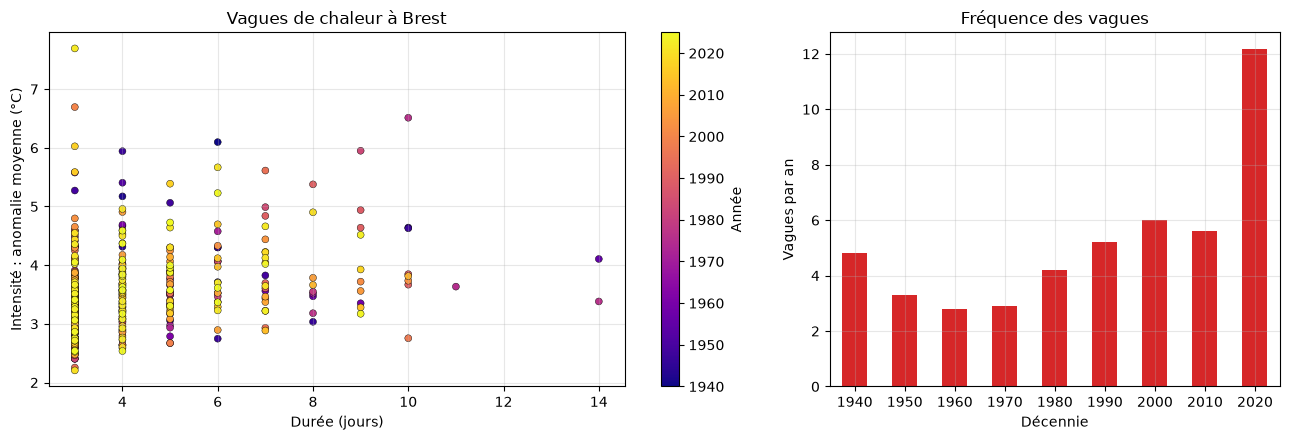

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
sc = a1.scatter(vagues.duree, vagues.intensite, c=vagues.annee, cmap='plasma', s=25, edgecolor='k', lw=.3)
fig.colorbar(sc, ax=a1, label='Année')
a1.set(xlabel='Durée (jours)', ylabel='Intensité : anomalie moyenne (°C)', title='Vagues de chaleur à Brest')

decennie = vagues.annee // 10 * 10
nb_annees = pd.Series(range(1940, 2026)).floordiv(10).mul(10).value_counts()   # la décennie 2020 n'a que 6 ans
(decennie.value_counts() / nb_annees).sort_index().plot.bar(ax=a2, rot=0, color='tab:red')
a2.set(xlabel='Décennie', ylabel='Vagues par an', title='Fréquence des vagues')
plt.tight_layout()
plt.show()

**Commentaire.** La plupart des vagues durent 3 à 5 jours avec une intensité de 2,5 à 5 °C. Il n'y a pas vraiment de
lien entre durée et intensité : les vagues les plus intenses sont souvent courtes. Les points jaunes (années récentes)
sont nombreux en haut à gauche : les épisodes courts et très chauds sont surtout récents.

Le signal le plus net est la fréquence (à droite, ramenée au nombre d'années de chaque décennie, car 2020 n'en compte
que 6) : environ 3 vagues par an dans les années 1960-1970, 6 dans les années 2000, et 12 par an sur 2020-2025.
Attention, le seuil est calculé sur toute la période 1940-2025 : dans un climat qui se réchauffe, il est un peu bas
pour les années récentes, ce qui donne plus de vagues à la fin. C'est justement le réchauffement qu'on observe ici.

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [6]:
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

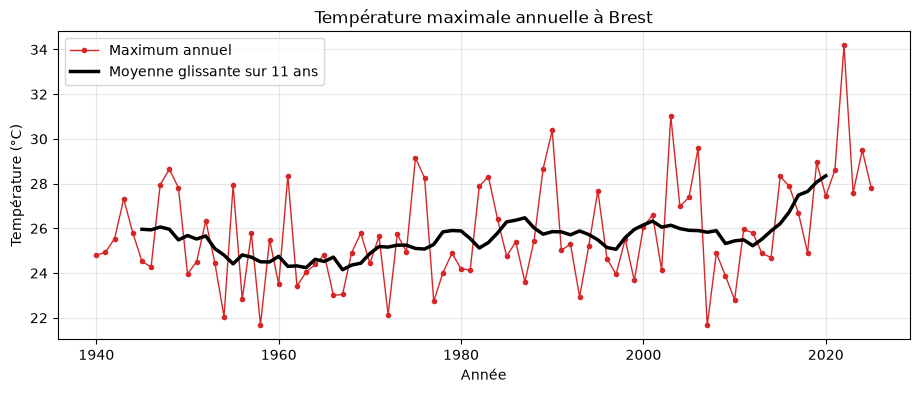

1940-1979 : moyenne 25.1 °C, écart-type 1.9 °C
1980-2025 : moyenne 26.3 °C, écart-type 2.4 °C


In [7]:
y = yearly_temp_brest.assign(annee=pd.to_datetime(yearly_temp_brest.valid_time).dt.year)

fig, ax = plt.subplots()
ax.plot(y.annee, y['max'], 'o-', ms=3, lw=1, color='tab:red', label='Maximum annuel')
ax.plot(y.annee, y['max'].rolling(11, center=True).mean(), lw=2.5, color='k', label='Moyenne glissante sur 11 ans')
ax.set(xlabel='Année', ylabel='Température (°C)', title='Température maximale annuelle à Brest')
ax.legend()
plt.show()
for a, b in [(1940, 1979), (1980, 2025)]:
    s = y.loc[y.annee.between(a, b), 'max']
    print(f'{a}-{b} : moyenne {s.mean():.1f} °C, écart-type {s.std():.1f} °C')

**Commentaire.** Le maximum annuel varie beaucoup d'une année à l'autre (de 21,7 à 34,2 °C), car il dépend de la
météo de quelques jours. La moyenne sur 11 ans est à peu près plate jusqu'aux années 1980, puis elle monte : 25,1 °C
en moyenne sur 1940-1979 contre 26,3 °C sur 1980-2025. Les années récentes sont aussi plus variables (écart-type
de 1,9 à 2,4 °C). Le record est 2022 avec 34,2 °C, bien au-dessus des autres années.

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

In [8]:
T = {'T brute': y['max']} | {f'T lissée {w} ans': y['max'].rolling(w, center=True).mean() for w in (5, 11, 21)}
CO2 = {'CO2': y.co2, 'ln(CO2)': np.log(y.co2), 'CO2²': y.co2**2}
print('Corrélation de Pearson entre Tmax annuelle et CO2 (1940-2025) :')
print(pd.DataFrame({c: {t: T[t].corr(CO2[c]) for t in T} for c in CO2}).round(2))

Corrélation de Pearson entre Tmax annuelle et CO2 (1940-2025) :
                  CO2  ln(CO2)  CO2²
T brute          0.31     0.30  0.32
T lissée 5 ans   0.49     0.47  0.51
T lissée 11 ans  0.61     0.60  0.62
T lissée 21 ans  0.83     0.82  0.83


**Commentaire.** La corrélation brute est faible ($r\approx0{,}31$) : une année donnée, la météo compte plus que le CO2.
Transformer le CO2 change peu de chose ($\ln$ CO2 : 0,30, CO2² : 0,32), car le CO2 ne va que de 310 à 428 ppm et sur
un si petit intervalle ces fonctions sont presque linéaires. Par contre, lisser la température augmente beaucoup la
corrélation (0,49 sur 5 ans, 0,61 sur 11 ans, 0,83 sur 21 ans) : on enlève le bruit d'une année à l'autre et il reste
la tendance, qui suit le CO2. Cela ne veut pas dire qu'on peut prédire le maximum d'une année précise : c'est pour ça
qu'on fait ensuite des prédictions probabilistes. On garde $\ln$ CO2 dans les modèles car c'est la forme physique
de l'effet de serre (le forçage radiatif est proportionnel à $\ln(C/C_0)$), même si ici les scores sont proches.

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [9]:
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


## Notre approche

On modélise la loi de la température extrême de l'année $t$ sachant le CO2 $C_t$ (ppm), avec la variable
$x_t=\ln(C_t/280)$ (l'effet de serre du CO2 est logarithmique, 280 ppm = niveau préindustriel).
Chaque modèle donne une **loi**, qu'on représente par $N=10\,000$ tirages Monte-Carlo par année.
On compare cinq modèles, chacun proposé par un membre du groupe :

1. **Référence** : $T_t=a+b\,x_t+\sigma\varepsilon_t$, $\varepsilon_t\sim\mathcal N(0,1)$, ajusté par moindres carrés.
2. **Régression bayésienne** (Christian) : même modèle, avec un a priori $p(a,b,\sigma^2)\propto\sigma^{-2}\mathbf 1_{b\ge0}$.
   On tire $\sigma^2\sim \mathrm{RSS}/\chi^2_{n-2}$ puis $(a,b)\mid\sigma^2\sim\mathcal N\big(\hat\beta,\sigma^2(X^\top X)^{-1}\big)$,
   en rejetant les tirages avec $b<0$. Chaque tirage de paramètres sert ensuite à tirer une année. L'incertitude sur
   la pente est ainsi prise en compte, ce qui compte beaucoup quand on extrapole jusqu'à 946 ppm.
3. **Régression quantile** (Yazid) : pour $\tau=0{,}01,\dots,0{,}99$, une droite $q_\tau(x)=a_\tau+b_\tau x$ minimise la
   perte pinball $\sum_i\rho_\tau(T_i-a_\tau-b_\tau x_i)+\alpha|b_\tau|$, avec $\rho_\tau(u)=u(\tau-\mathbf 1_{u<0})$.
   On trie les 99 quantiles (pour éviter qu'ils se croisent) puis on tire $U\sim\mathcal U(0,1)$ et $T=q_U(x)$ par interpolation.
4. **GEV non stationnaire** (Reda, pour les maxima) : la théorie des valeurs extrêmes dit que le maximum de nombreuses
   valeurs suit une loi GEV,
   $$F(t)=\exp\Big\{-\big[1+\xi\tfrac{t-\mu_t}{\sigma}\big]^{-1/\xi}\Big\},\qquad \mu_t=\beta_0+\beta_1x_t .$$
   Les paramètres $(\beta_0,\beta_1,\log\sigma,\xi)$ minimisent la log-vraisemblance négative avec PyTorch (Adam),
   avec $\beta_1\ge0$ et $\xi\in[-0{,}5;-0{,}01]$ (queue bornée, classique pour des températures). On entraîne
   200 modèles sur des rééchantillonnages bootstrap des années pour avoir l'incertitude sur les paramètres, puis on
   tire par inversion : $T=\mu+\frac\sigma\xi\big[(-\ln U)^{-\xi}-1\big]$.
   Pour les minima, Reda utilise plutôt un **bootstrap des résidus** de la droite (aucune loi supposée).
5. **Générateur neuronal entraîné au CRPS** (Elias) : $T_t=a+b\,x_t+s\,g_\phi(\eta)$, où $g_\phi$ est un petit réseau
   (2 couches de 32 neurones) qui transforme un bruit $\eta\sim\mathcal N(0,I_2)$ en résidu. Il est entraîné en
   minimisant le CRPS de ses tirages (32 tirages par année observée) :
   $$\mathcal L=\frac1M\sum_m|\hat T_m-T|-\frac{1}{2M(M-1)}\sum_{m\ne l}|\hat T_m-\hat T_l| .$$
   Le réseau apprend donc la forme des résidus sans hypothèse de loi. La droite $(a,b)$ est rééchantillonnée par
   bootstrap pour garder l'incertitude sur la tendance.

**Score.** On compare les modèles avec le CRPS (en °C, plus c'est bas mieux c'est), qui mesure l'écart entre toute la
loi prédite $F$ et la valeur observée $y$ :
$$\mathrm{CRPS}(F,y)=\mathbb E|X-y|-\tfrac12\mathbb E|X-X'|,\qquad X,X'\sim F\ \text{indépendants}.$$

**Choix du modèle.** On découpe 1971–2000 en trois blocs de 10 ans ; chaque bloc est prédit par le modèle ajusté sur
toutes les années d'avant (**validation**), et on retient le modèle qui a le meilleur CRPS moyen. Si plusieurs
modèles sont à moins de 0,01 °C du meilleur, on prend le plus simple (dans l'ordre de la liste ci-dessus) : un
écart aussi petit change d'une graine aléatoire à l'autre, il ne veut rien dire. Pour vérifier ce choix, on ajuste ensuite sur 1940–2000 et on note sur 2001–2025
(**test**, des années plus riches en CO2 que tout l'entraînement). Les projections jusqu'en 2100 utilisent enfin le
modèle retenu, réajusté sur 1940–2025.

In [10]:
C0, N = 280, 10_000

def fit_ref(x, t):
    b, a = np.polyfit(x, t, 1)
    return a, b, np.std(t - a - b * x, ddof=2)

def tirer_ref(m, x, n=N):
    a, b, s = m
    return a + b * x + s * rng.standard_normal((n, len(x)))

def fit_bayes(x, t):                               # Christian
    X = np.c_[np.ones_like(x), x]
    V = np.linalg.inv(X.T @ X)
    beta = V @ X.T @ t
    return beta, V, np.sum((t - X @ beta) ** 2), len(t) - 2

def tirer_bayes(m, x, n=N):
    beta, V, rss, ddl = m
    tirs = []
    while sum(len(v) for v in tirs) < n:
        s = np.sqrt(rss / rng.chisquare(ddl, n))
        ab = beta + s[:, None] * rng.standard_normal((n, 2)) @ np.linalg.cholesky(V).T
        tirs.append(np.c_[ab, s][ab[:, 1] >= 0])  # rejet des pentes négatives
    a, b, s = np.concatenate(tirs)[:n].T[:, :, None]
    return a + b * x + s * rng.standard_normal((n, len(x)))

TAU = np.arange(1, 100) / 100
def fit_qr(x, t, alpha=0):                         # Yazid
    xm, xs = x.mean(), x.std()                     # x centré-réduit pour que la pénalité ait du sens
    f = [QuantileRegressor(quantile=q, alpha=alpha, solver='highs').fit(((x - xm) / xs)[:, None], t) for q in TAU]
    return xm, xs, np.array([r.intercept_ for r in f]), np.array([r.coef_[0] for r in f])

def tirer_qr(m, x, n=N):
    xm, xs, a, b = m
    q = np.sort(a + np.outer((x - xm) / xs, b), axis=1)   # tri : les quantiles ne se croisent plus
    u = rng.random((n, len(x)))
    return np.stack([np.interp(u[:, i], TAU, q[i]) for i in range(len(x))], axis=1)

def fit_gev(x, t, B=200, pas=3000):                # Reda
    x, t = torch.tensor(x), torch.tensor(t)
    i = torch.randint(len(t), (B, len(t)))
    i[0] = torch.arange(len(t))                    # le modèle 0 est ajusté sur les vraies données
    xb, tb = x[i], t[i]
    theta = torch.tensor([t.mean().item(), 0., t.std().log().item(), -.1], dtype=torch.float64).repeat(B, 1)
    theta.requires_grad_()
    opt = torch.optim.Adam([theta], lr=.02)
    for _ in range(pas):
        b0, b1, log_s, xi = theta.T[:, :, None]
        z = (1 + xi * (tb - b0 - b1 * xb) / log_s.exp()).clamp_min(1e-6)
        nll = (log_s + (1 + 1 / xi) * z.log() + z ** (-1 / xi)).sum()
        opt.zero_grad(); nll.backward(); opt.step()
        with torch.no_grad():
            theta[:, 1].clamp_(min=0)              # plus de CO2 ne refroidit pas
            theta[:, 3].clamp_(-.5, -.01)
    return theta.detach().numpy()

def tirer_gev(theta, x, n=N):
    b0, b1, log_s, xi = theta[rng.integers(len(theta), size=n)].T[:, :, None]
    return b0 + b1 * x + np.exp(log_s) / xi * ((-np.log(rng.random((n, len(x))))) ** (-xi) - 1)

def bootstrap_droites(x, t, B=200):
    i = [np.arange(len(t))] + [rng.integers(len(t), size=len(t)) for _ in range(B - 1)]
    return [np.polyfit(x[j], t[j], 1)[::-1] for j in i] , i

def fit_residus(x, t):                             # Reda (minima)
    droites, i = bootstrap_droites(x, t)
    return [(a, b, t[j] - a - b * x[j]) for (a, b), j in zip(droites, i)]

def tirer_residus(m, x, n=N):
    out = np.empty((n, len(x)))
    for k, j in enumerate(rng.integers(len(m), size=n)):
        a, b, r = m[j]
        out[k] = a + b * x + rng.choice(r, size=len(x))
    return out

def crps_torch(X, y):
    M = X.shape[1]
    return ((X - y[:, None]).abs().mean()
            - (X[:, :, None] - X[:, None, :]).abs().sum((1, 2)).mean() / (2 * M * (M - 1)))

def fit_nn(x, t, pas=1500):                        # Elias
    a, b, s = fit_ref(x, t)
    z = torch.tensor((t - a - b * x) / s, dtype=torch.float32)   # résidus réduits
    torch.manual_seed(0)
    g = torch.nn.Sequential(torch.nn.Linear(2, 32), torch.nn.SiLU(), torch.nn.Linear(32, 32), torch.nn.SiLU(),
                            torch.nn.Linear(32, 1))
    opt = torch.optim.Adam(g.parameters(), lr=1e-3)
    for _ in range(pas):
        zb = z[torch.randint(len(z), (64,))]
        perte = crps_torch(g(torch.randn(64, 32, 2)).squeeze(-1), zb)
        opt.zero_grad(); perte.backward(); opt.step()
    return g, s, np.array(bootstrap_droites(x, t)[0])

def tirer_nn(m, x, n=N):
    g, s, droites = m
    with torch.no_grad():
        z = g(torch.randn(n, len(x), 2)).squeeze(-1).numpy()
    a, b = droites[rng.integers(len(droites), size=n)].T
    return a[:, None] + b[:, None] * x + s * z

def crps(tirages, obs):
    """CRPS moyen (°C) ; tirages (n, nb_années), obs (nb_années,)."""
    s = np.sort(tirages, axis=0)
    n = len(s)
    w = (2 * np.arange(1, n + 1) - n - 1) / n**2
    return np.mean(np.abs(s - obs).mean(axis=0) - w @ s)

MODELES = {'max': {'Référence': (fit_ref, tirer_ref), 'Bayes': (fit_bayes, tirer_bayes), 'Quantiles': (fit_qr, tirer_qr),
                   'GEV': (fit_gev, tirer_gev), 'Neuronal': (fit_nn, tirer_nn)}}
# pour les minima, le bootstrap des résidus de Reda remplace la GEV (ordre = du plus simple au plus complexe)
MODELES['min'] = {k: v for k, v in MODELES['max'].items() if k != 'GEV'}
MODELES['min'] = {**dict(list(MODELES['min'].items())[:3]), 'Bootstrap résidus': (fit_residus, tirer_residus),
                  'Neuronal': (fit_nn, tirer_nn)}

In [11]:
x = np.log(y.co2.to_numpy() / C0)
# validation : 3 blocs de 10 ans, chacun prédit avec les années d'avant ; test : 2001-2025 appris sur 1940-2000
blocs = [(y.annee < a, y.annee.between(a, a + 9)) for a in (1971, 1981, 1991)]
test = (y.annee <= 2000, y.annee > 2000)

def comparer(var):
    t = y[var].to_numpy()
    score = lambda fit, tirer, a, b: crps(tirer(fit(x[a], t[a]), x[b]), t[b])
    res = pd.DataFrame({nom: {'validation 1971-2000': np.mean([score(f, g, a, b) for a, b in blocs]),
                              'test 2001-2025': score(f, g, *test)}
                        for nom, (f, g) in MODELES[var].items()}).T.sort_values('validation 1971-2000')
    # écart < 0,01 °C = pas significatif (ça change d'une graine à l'autre) : on garde alors le plus simple
    meilleur = res['validation 1971-2000'].min()
    choix = next(nom for nom in MODELES[var] if res.loc[nom, 'validation 1971-2000'] < meilleur + 0.01)
    print(f'CRPS (°C) pour T{var} :\n{res.round(3)}\n=> modèle retenu : {choix}')
    return choix

choix_max = comparer('max')

CRPS (°C) pour Tmax :
           validation 1971-2000  test 2001-2025
Bayes                     1.166           1.574
GEV                       1.168           1.660
Neuronal                  1.333           1.726
Référence                 1.339           1.701
Quantiles                 1.381           1.806
=> modèle retenu : Bayes


**Commentaire.** En validation, Bayes et la GEV sont à égalité (1,166 et 1,168 °C) : on retient **Bayes**, le plus
simple des deux. Le test sur 2001-2025 confirme ce choix : Bayes y a le meilleur score (1,57 °C), devant la GEV
(1,66 °C) et la référence (1,70 °C). Ce qui aide Bayes, c'est la prise en compte de l'incertitude sur la pente :
les intervalles s'élargissent quand le CO2 sort de ce qu'on a vu à l'entraînement, ce qui est le cas sur 2001-2025.

Le réseau de neurones ne fait pas mieux que la référence : avec seulement 30 à 60 années pour apprendre, il ne
trouve rien de plus qu'une loi proche d'une gaussienne. La régression quantile est la moins bonne : ajuster 99 droites
sur si peu de points rend les quantiles extrêmes instables.

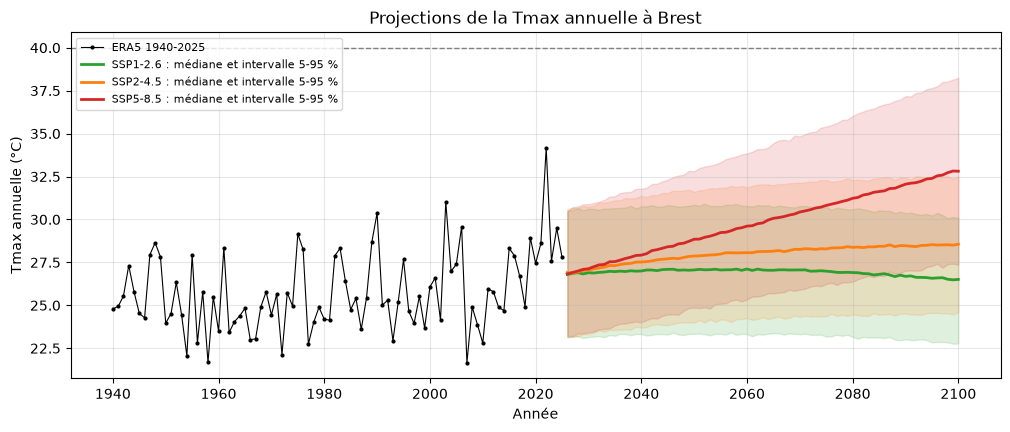

In [12]:
futur = yearly_future_co2.assign(annee=pd.to_datetime(yearly_future_co2.valid_time).dt.year)
SSP = {'ssp1-2.6': 'tab:green', 'ssp2-4.5': 'tab:orange', 'ssp5-8.5': 'tab:red'}

def projeter(var, nom):
    """Réajuste le modèle sur 1940-2025 et tire 10 000 trajectoires 2026-2100 par scénario."""
    fit, tirer = MODELES[var][nom]
    m = fit(x, y[var].to_numpy())
    return {s: tirer(m, np.log(futur[s].to_numpy() / C0)) for s in SSP}

def tracer(var, sims, seuil):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(y.annee, y[var], 'k.-', lw=.8, ms=4, label='ERA5 1940-2025')
    for s, col in SSP.items():
        q5, q50, q95 = np.percentile(sims[s], [5, 50, 95], axis=0)
        ax.fill_between(futur.annee, q5, q95, color=col, alpha=.15)
        ax.plot(futur.annee, q50, color=col, lw=2, label=f'{s.upper()} : médiane et intervalle 5-95 %')
    ax.axhline(seuil, color='grey', ls='--', lw=1)
    ax.set(xlabel='Année', ylabel=f'T{var} annuelle (°C)', title=f'Projections de la T{var} annuelle à Brest')
    ax.legend(loc='upper left', fontsize=8)
    plt.show()

sims_max = projeter('max', choix_max)
tracer('max', sims_max, 40)

**Commentaire.** Les trois scénarios partent du même niveau en 2026 (médiane d'environ 27 °C) puis s'écartent. Avec
SSP1-2.6 le CO2 redescend à 400 ppm et la médiane revient à 26,5 °C en 2100. Avec SSP2-4.5 elle atteint 28,6 °C et
avec SSP5-8.5 (946 ppm) 32,8 °C : une année normale de 2100 serait alors aussi chaude que les années les plus chaudes
observées jusqu'ici. Les bandes 5-95 % sont larges (environ 7 °C en 2026, 11 °C en 2100 pour SSP5-8.5) : la météo d'une
année reste très variable, et l'incertitude sur la pente pèse de plus en plus quand le CO2 augmente.

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

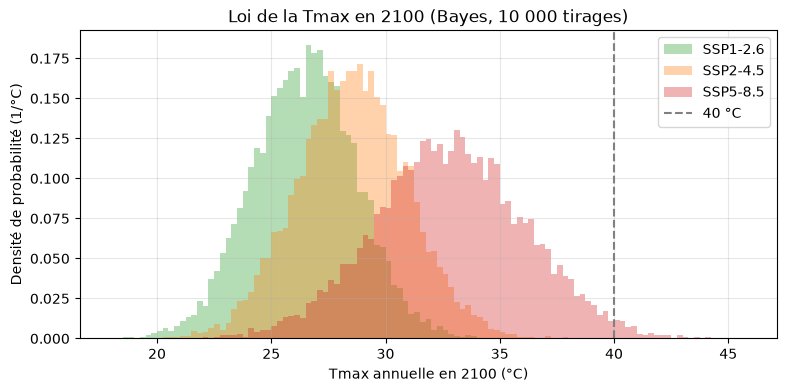

          CO2 2100 (ppm)  q5 2100 (°C)  q50 2100 (°C)  q95 2100 (°C)  P(T 2100 > 40 °C)  P(au moins une fois 2026-2100)
SSP1-2.6        400.0000       22.7740        26.5086        30.1013             0.0000                          0.0000
SSP2-4.5        526.9874       24.6031        28.5569        32.5015             0.0000                          0.0002
SSP5-8.5        946.2222       27.3744        32.8101        38.2479             0.0147                          0.0771



           médiane 2100 SSP5-8.5 (°C)  P(T 2100 > 40 °C), SSP5-8.5
Référence                      32.836                        0.001
Bayes                          32.903                        0.015
Quantiles                      31.687                        0.059
GEV                            31.399                        0.012
Neuronal                       32.698                        0.023


In [13]:
def resume_2100(sims, seuil, au_dessus=True):
    lignes = {}
    for s, t in sims.items():
        ev = t > seuil if au_dessus else t < seuil
        lignes[s.upper()] = {'CO2 2100 (ppm)': futur[s].iloc[-1],
                             **{f'q{p} 2100 (°C)': np.percentile(t[:, -1], p) for p in (5, 50, 95)},
                             f'P(T 2100 {">" if au_dessus else "<"} {seuil} °C)': ev[:, -1].mean(),
                             'P(au moins une fois 2026-2100)': ev.any(axis=1).mean()}
    return pd.DataFrame(lignes).T

fig, ax = plt.subplots(figsize=(9, 4))
for s, col in SSP.items():
    ax.hist(sims_max[s][:, -1], np.arange(18, 46, .25), density=True, histtype='stepfilled', alpha=.35,
            color=col, label=s.upper())
ax.axvline(40, color='grey', ls='--', label='40 °C')
ax.set(xlabel='Tmax annuelle en 2100 (°C)', ylabel='Densité de probabilité (1/°C)',
       title=f'Loi de la Tmax en 2100 ({choix_max}, 10 000 tirages)')
ax.legend()
plt.show()
print(resume_2100(sims_max, 40).round(4).to_string())

def selon_modele(var, seuil, au_dessus=True):
    """Même calcul avec les autres modèles, pour voir à quel point le résultat en dépend."""
    lignes = {}
    for nom in MODELES[var]:
        t = projeter(var, nom)['ssp5-8.5'][:, -1]
        lignes[nom] = {'médiane 2100 SSP5-8.5 (°C)': np.median(t),
                       f'P(T 2100 {">" if au_dessus else "<"} {seuil} °C), SSP5-8.5': np.mean(t > seuil if au_dessus else t < seuil)}
    print(pd.DataFrame(lignes).T.round(3).to_string())

print()
selon_modele('max', 40)

**Réponse.** Avec Bayes, la probabilité de dépasser 40 °C à Brest :

| Scénario | Médiane 2100 | P(Tmax 2100 > 40 °C) | P(au moins une année > 40 °C entre 2026 et 2100) |
|---|---|---|---|
| SSP1-2.6 | 26,5 °C | ≈ 0 | ≈ 0 |
| SSP2-4.5 | 28,6 °C | ≈ 0 | ≈ 0,02 % |
| SSP5-8.5 | 32,8 °C | 1,5 % | 7,7 % |

**Commentaire.** Dépasser 40 °C reste rare pour une année donnée, même en 2100 avec SSP5-8.5 (1,5 %). Sur 75 ans, le
risque s'accumule : dans ce scénario, environ 1 trajectoire sur 13 dépasse 40 °C au moins une fois. Avec 10 000
tirages, « 0 » veut seulement dire moins d'environ 1 chance sur 10 000, pas que c'est impossible.

Le deuxième tableau montre que ce chiffre dépend beaucoup du modèle : la médiane 2100 bouge peu (31,4 à 32,9 °C),
mais la probabilité de dépasser 40 °C va de 0,1 % (référence, qui ignore l'incertitude sur la pente) à 5,9 %
(quantiles). C'est logique : 40 °C est loin de tout ce qui a été observé (34,2 °C au maximum), donc le résultat dépend
surtout de la forme de la queue de la loi, que 86 années ne suffisent pas à bien connaître. Il faut aussi garder en
tête que le CO2 est la seule entrée du modèle (pas de circulation atmosphérique, ni d'océan) et qu'on extrapole
jusqu'à 946 ppm alors qu'on n'a observé que 310 à 428 ppm.

Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

Corrélation Tmin / ln(CO2) : 0.15



CRPS (°C) pour Tmin :
                   validation 1971-2000  test 2001-2025
Référence                         1.221           1.138
Bayes                             1.222           0.984
Bootstrap résidus                 1.224           1.106
Neuronal                          1.237           1.120
Quantiles                         1.311           1.068
=> modèle retenu : Référence


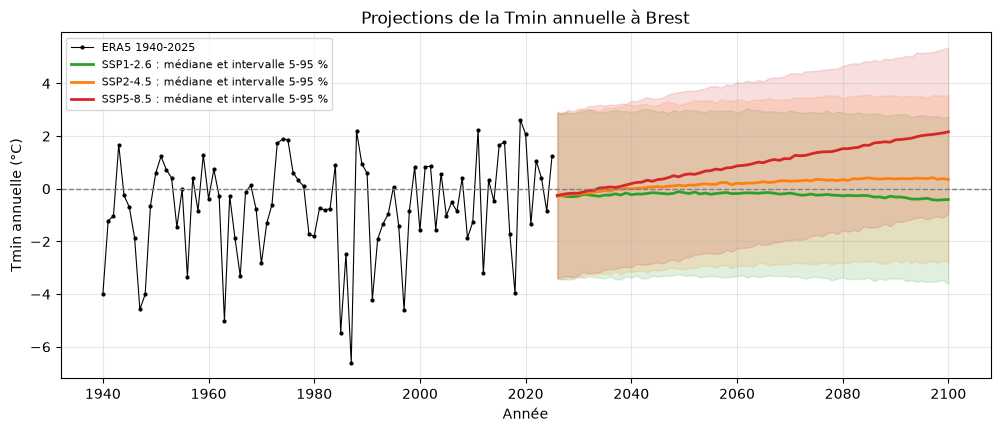

          CO2 2100 (ppm)  q5 2100 (°C)  q50 2100 (°C)  q95 2100 (°C)  P(T 2100 < 0 °C)  P(au moins une fois 2026-2100)
SSP1-2.6         400.000        -3.606         -0.407          2.757             0.586                             1.0
SSP2-4.5         526.987        -2.783          0.357          3.554             0.425                             1.0
SSP5-8.5         946.222        -0.948          2.164          5.356             0.126                             1.0



                   médiane 2100 SSP5-8.5 (°C)  P(T 2100 < 0 °C), SSP5-8.5
Référence                               2.192                       0.126
Bayes                                   2.516                       0.165
Quantiles                               3.093                       0.275
Bootstrap résidus                       2.207                       0.214
Neuronal                                2.209                       0.229


In [14]:
print(f"Corrélation Tmin / ln(CO2) : {y['min'].corr(np.log(y.co2)):.2f}\n")
choix_min = comparer('min')
sims_min = projeter('min', choix_min)
tracer('min', sims_min, 0)
print(resume_2100(sims_min, 0, au_dessus=False).round(3).to_string())
print()
selon_modele('min', 0, au_dessus=False)

**Approche.** On reprend les mêmes modèles, mais la GEV, faite pour les maxima, est remplacée par le **bootstrap des
résidus** de Reda : on ajuste la droite sur un rééchantillonnage des années, puis on ajoute un résidu tiré parmi les
résidus observés, sans supposer de loi.

**Commentaire.** Le minimum annuel est encore moins lié au CO2 que le maximum ($r=0{,}15$) : il dépend surtout de
quelques vagues de froid (−6,6 °C en 1987). En validation, la référence, Bayes et le bootstrap des résidus sont à
moins de 0,01 °C les uns des autres, donc on garde la **référence**, le plus simple. Sur le test, c'est cette fois Bayes
qui fait le mieux (0,98 °C contre 1,14 °C) : la validation ne pouvait pas le voir, les écarts sur 1971-2000 étaient trop
petits.

Les minima remontent avec le CO2 : la médiane 2100 vaut −0,4 °C (SSP1-2.6), 0,4 °C (SSP2-4.5) et 2,2 °C (SSP5-8.5).
La probabilité que le minimum de 2100 soit sous 0 °C passe de 59 % à 13 %. Il gèlera encore au moins une fois d'ici
2100 dans tous les scénarios (100 % des trajectoires), mais les hivers sans gel deviennent fréquents avec SSP5-8.5.
Les autres modèles donnent des résultats proches (médiane de 2,2 à 3,1 °C, P(< 0 °C) de 13 % à 28 % pour SSP5-8.5).

# Conclusion

- **Le passé.** Brest a un cycle saisonnier doux, typique d'un climat océanique. Les vagues de chaleur (au-dessus du
  quantile 90 % de la saison) sont devenues bien plus fréquentes depuis les années 1980, et la plus intense est celle
  de juillet 2022.
- **Le futur.** Le lien entre les extrêmes annuels et le CO2 est faible d'une année à l'autre, mais net sur la
  tendance. Parmi nos cinq modèles, la régression bayésienne est retenue pour les maxima : elle est la meilleure en
  validation et sur 2001-2025 (CRPS 1,57 °C contre 1,70 °C pour la référence). En 2100, la médiane du maximum annuel
  va de 26,5 °C (SSP1-2.6) à 32,8 °C (SSP5-8.5). Dépasser 40 °C reste rare une année donnée (1,5 % en 2100 avec
  SSP5-8.5), mais atteint 7,7 % sur l'ensemble 2026-2100 dans ce scénario. Pour les minima, le gel devient moins
  fréquent sans disparaître.
- **Limites.** 86 années, c'est peu pour connaître la queue de la loi : la probabilité de 40 °C en 2100 (SSP5-8.5)
  va de 0,1 % à 5,9 % selon le modèle. Le CO2 est notre seule variable explicative, et les scénarios nous font extrapoler bien au-delà
  des concentrations observées.